# Predicción de zonas susceptibles a incendios forestales en Petén
### Modelado con Random Forest y generación de mapas de susceptibilidad

**Universidad del Valle de Guatemala · Trabajo profesional**
Silvia Alejandra Illescas Fernández

Este notebook contiene el entrenamiento y la evaluación del modelo Random Forest, la generación de los mapas anuales de susceptibilidad (2015–2025), los mapas integrados y las tablas y figuras utilizadas en el documento.

| Sección | Contenido |
|---|---|
| 1 | Entorno de trabajo |
| 2 | Carga del conjunto de datos |
| 3 | Variables predictoras y división de los datos |
| 4 | Entrenamiento del modelo |
| 5 | Evaluación del modelo |
| 6 | Importancia de las variables |
| 7 | Guardado del modelo |
| 8 | Generación de los mapas anuales de susceptibilidad |
| 9 | Mapa integrado 2015–2025 y clasificación |
| 10 | Mapa integrado 2017–2024 |
| 11 | Estadísticas anuales |
| 12 | Figuras y tablas para el documento |

## 1. Entorno de trabajo
Versiones de las bibliotecas utilizadas.

In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Pandas: 2.3.1
NumPy: 2.3.1
Scikit-learn: 1.8.0


In [2]:
import geopandas as gpd

print("GeoPandas:", gpd.__version__)

GeoPandas: 1.1.4


## 2. Carga del conjunto de datos
Conjunto de observaciones de presencia (1) y pseudoausencia (0) de fuego con los valores de las siete variables predictoras, en EPSG:32616.

In [4]:
import geopandas as gpd

ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\dataset_modelo\dataset_modelado_2015_2025_limpio.shp"

datos = gpd.read_file(ruta)

print("Registros:", len(datos))
print("Columnas:", datos.columns.tolist())

Registros: 290122
Columnas: ['id', 'fire_1', 'presencia', 'anio', 'elev_1', 'pend_1', 'cob_1', 'vias_1', 'pob_1', 'precip_1', 'temp_1', 'fid', 'latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'layer', 'path', 'geometry']


In [9]:
datos["presencia"] = datos["presencia"].astype(int)

print(datos["presencia"].dtype)
print(datos["presencia"].value_counts())

int64
presencia
0    145218
1    144904
Name: count, dtype: int64


## 3. Variables predictoras y división de los datos
Siete variables predictoras y división estratificada: 80 % entrenamiento y 20 % prueba (`random_state = 42`).

In [11]:
# Variables predictoras
variables = [
    "elev_1",
    "pend_1",
    "cob_1",
    "vias_1",
    "pob_1",
    "precip_1",
    "temp_1"
]

X = datos[variables]
y = datos["presencia"]

# Nueva división 80/20
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Tipo de presencia:", y.dtype)
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("\nClases en prueba:")
print(y_test.value_counts())

Tipo de presencia: int64
Entrenamiento: (232097, 7)
Prueba: (58025, 7)

Clases en prueba:
presencia
0    29044
1    28981
Name: count, dtype: int64


## 4. Entrenamiento del modelo Random Forest
300 árboles de decisión (`n_estimators = 300`).

In [12]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

print("Random Forest entrenado correctamente.")
print("Clases del modelo:", modelo_rf.classes_)

Random Forest entrenado correctamente.
Clases del modelo: [0 1]


## 5. Evaluación del modelo
Métricas sobre el conjunto de prueba, matriz de confusión y curva ROC.

In [13]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predicciones
y_pred = modelo_rf.predict(X_test)
y_prob = modelo_rf.predict_proba(X_test)[:, 1]

# Métricas
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.73170185264972
Balanced Accuracy: 0.7317497374353625
Precision: 0.7125202015400703
Recall: 0.775853145164073
F1-score: 0.7428392084310681
ROC-AUC: 0.8154851682504389

Matriz de confusión:
[[19972  9072]
 [ 6496 22485]]


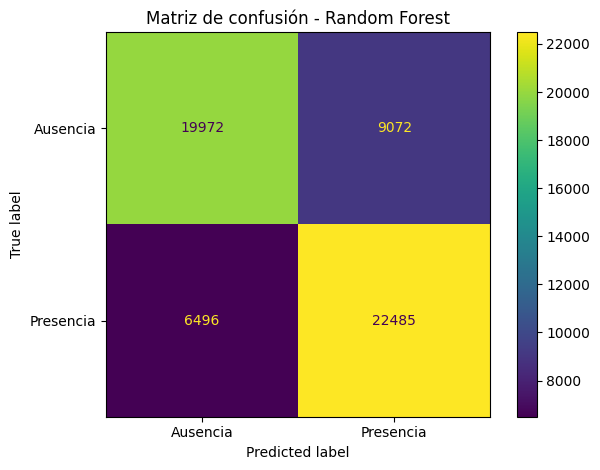

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Ausencia", "Presencia"],
    values_format="d"
)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

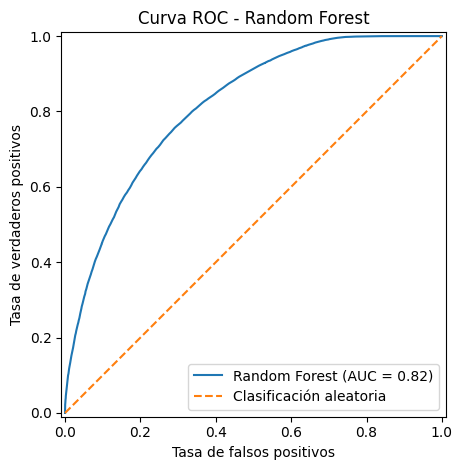

In [17]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.plot([0, 1], [0, 1], "--", label="Clasificación aleatoria")
plt.title("Curva ROC - Random Forest")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Importancia de las variables

In [14]:
import pandas as pd

importancias = pd.DataFrame({
    "Variable": variables,
    "Importancia": modelo_rf.feature_importances_
}).sort_values(
    by="Importancia",
    ascending=False
)

print(importancias)

   Variable  Importancia
4     pob_1     0.189386
5  precip_1     0.175390
6    temp_1     0.168893
0    elev_1     0.158899
3    vias_1     0.149724
1    pend_1     0.130654
2     cob_1     0.027055


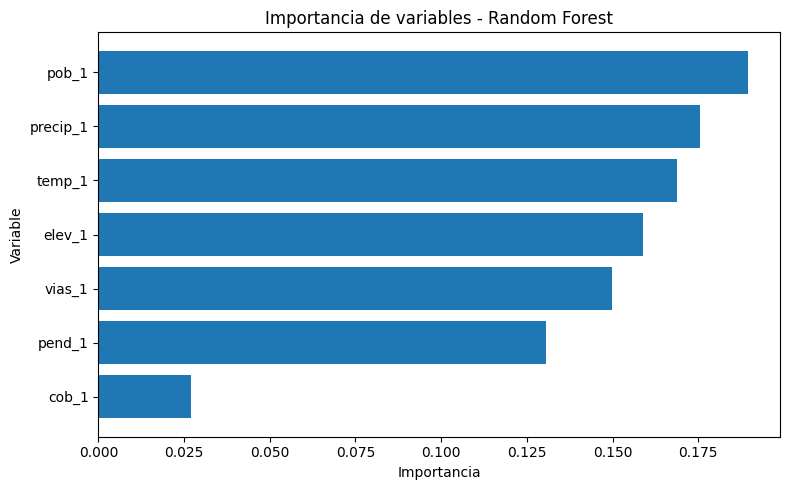

In [15]:
import matplotlib.pyplot as plt

importancias_ordenadas = importancias.sort_values(
    "Importancia",
    ascending=True
)

plt.figure(figsize=(8, 5))

plt.barh(
    importancias_ordenadas["Variable"],
    importancias_ordenadas["Importancia"]
)

plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Importancia de variables - Random Forest")
plt.tight_layout()

plt.show()

## 7. Guardado del modelo

In [18]:
import joblib
import os

carpeta_modelo = r"C:\Users\Silvia\Documents\GradIncendiosPeten\modelado"
ruta_modelo = os.path.join(carpeta_modelo, "random_forest_incendios.pkl")

joblib.dump(modelo_rf, ruta_modelo)

print("Modelo guardado en:")
print(ruta_modelo)

Modelo guardado en:
C:\Users\Silvia\Documents\GradIncendiosPeten\modelado\random_forest_incendios.pkl


## 8. Generación de los mapas anuales de susceptibilidad
El modelo se aplica píxel a píxel (30 m) a las variables de cada año, procesando los rásteres por bloques de 1024 píxeles. Las celdas sin datos válidos conservan el valor −9999.

### 8.1 Carpeta de salida y variables de 2015

In [41]:
import os

carpeta_mapas = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad"

os.makedirs(carpeta_mapas, exist_ok=True)

print("Carpeta creada:")
print(carpeta_mapas)

Carpeta creada:
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad


In [42]:
raster_2015 = {
    "elev_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\topografia\dem_peten_utm.tif",
    "pend_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\topografia\pendiente_peten.tif",
    "cob_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\worldcover\worldcover_peten_30m_final.tif",
    "vias_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\vias\distancia_vias.tif",
    "pob_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\poblados\distancia_poblados.tif",
    "precip_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\chirps_anual\precip_2015_30m_final1.tif",
    "temp_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\temperature_anual\tmax_2015_30m.tif"
}

for variable, ruta in raster_2015.items():
    print(variable, "→", os.path.exists(ruta))

elev_1 → True
pend_1 → True
cob_1 → True
vias_1 → True
pob_1 → True
precip_1 → True
temp_1 → True


### 8.2 Carga del modelo guardado

In [43]:
import joblib

ruta_modelo = r"C:\Users\Silvia\Documents\GradIncendiosPeten\modelado\random_forest_incendios.pkl"

modelo = joblib.load(ruta_modelo)

print("Modelo cargado correctamente")
print("Clases:", modelo.classes_)
print("Número de variables:", modelo.n_features_in_)
print("Variables:", modelo.feature_names_in_)

Modelo cargado correctamente
Clases: [0 1]
Número de variables: 7
Variables: ['elev_1' 'pend_1' 'cob_1' 'vias_1' 'pob_1' 'precip_1' 'temp_1']


### 8.3 Prueba en un bloque de 500 × 500 píxeles
Verificación de que el modelo genera probabilidades válidas antes de procesar todo el departamento.

In [47]:
from rasterio.windows import Window

# Bloque de 500 x 500 aproximadamente en el centro
ventana = Window(3900, 3600, 500, 500)

datos_bloque = {}

for variable in variables:
    with rasterio.open(raster_2015[variable]) as src:
        datos_bloque[variable] = src.read(
            1,
            window=ventana
        ).flatten()

df_prueba = pd.DataFrame(datos_bloque)

mascara_valida = (
    (df_prueba["elev_1"] != -9999) &
    (df_prueba["pend_1"] != -9999) &
    (df_prueba["cob_1"] != 0) &
    (df_prueba["precip_1"] != -9999) &
    (df_prueba["temp_1"] != -9999) &
    np.isfinite(df_prueba["vias_1"]) &
    np.isfinite(df_prueba["pob_1"])
)

df_valido = df_prueba.loc[mascara_valida, variables]

print("Píxeles totales:", len(df_prueba))
print("Píxeles válidos:", len(df_valido))
print("Píxeles excluidos:", (~mascara_valida).sum())
print("\nEjemplo:")
print(df_valido.head())

Píxeles totales: 250000
Píxeles válidos: 250000
Píxeles excluidos: 0

Ejemplo:
       elev_1     pend_1  cob_1       vias_1         pob_1     precip_1  \
0  298.944794   4.889784     30  1842.009766  48891.246094  2087.407227   
1  297.291321  11.437738     30  1838.831177  48861.464844  2087.524414   
2  297.656219  18.207033     30  1836.137207  48831.679688  2087.641846   
3  302.187317  21.728380     30  1833.930298  48801.894531  2087.759033   
4  307.500671  23.863146     30  1832.211792  48772.113281  2087.876221   

      temp_1  
0  31.957932  
1  31.957478  
2  31.957024  
3  31.956570  
4  31.956116  


In [48]:
probabilidades = modelo.predict_proba(df_valido)[:, 1]

print("Cantidad de predicciones:", len(probabilidades))
print("Mínimo:", probabilidades.min())
print("Máximo:", probabilidades.max())
print("Promedio:", probabilidades.mean())

print("\nPrimeras 10 probabilidades:")
print(probabilidades[:10])

Cantidad de predicciones: 250000
Mínimo: 0.04666666666666667
Máximo: 0.9233333333333333
Promedio: 0.4490757691111111

Primeras 10 probabilidades:
[0.53       0.54666667 0.58       0.61       0.59666667 0.58
 0.45333333 0.46666667 0.34       0.39      ]


### 8.4 Mapa 2016

In [51]:
import rasterio
import numpy as np
import pandas as pd
import os
import math
from rasterio.windows import Window

# Rásteres para 2016
raster_2016 = {
    "elev_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\topografia\dem_peten_utm.tif",
    "pend_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\topografia\pendiente_peten.tif",
    "cob_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\worldcover\worldcover_peten_30m_final.tif",
    "vias_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\vias\distancia_vias.tif",
    "pob_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\poblados\distancia_poblados.tif",
    "precip_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\chirps_anual\precip_2016_30m.tif",
    "temp_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\temperature_anual\tmax_2016_30m.tif"
}

salida_2016 = os.path.join(
    carpeta_mapas,
    "susceptibilidad_2016.tif"
)

tam_bloque = 1024

# Abrir rásteres
srcs = {
    variable: rasterio.open(ruta)
    for variable, ruta in raster_2016.items()
}

referencia = srcs["elev_1"]

perfil = referencia.profile.copy()
perfil.update(
    dtype="float32",
    count=1,
    nodata=-9999.0,
    compress="lzw"
)

filas_bloques = math.ceil(referencia.height / tam_bloque)
columnas_bloques = math.ceil(referencia.width / tam_bloque)
total_bloques = filas_bloques * columnas_bloques

contador = 0

with rasterio.open(salida_2016, "w", **perfil) as dst:

    for fila in range(0, referencia.height, tam_bloque):
        for columna in range(0, referencia.width, tam_bloque):

            alto = min(tam_bloque, referencia.height - fila)
            ancho = min(tam_bloque, referencia.width - columna)

            ventana = Window(
                columna,
                fila,
                ancho,
                alto
            )

            datos = {}

            for variable in variables:
                datos[variable] = srcs[variable].read(
                    1,
                    window=ventana
                ).ravel()

            df = pd.DataFrame(datos)

            mascara = (
                (df["elev_1"] != -9999) &
                (df["pend_1"] != -9999) &
                (df["cob_1"] != 0) &
                (df["precip_1"] != -9999) &
                (df["temp_1"] != -9999) &
                np.isfinite(df["vias_1"]) &
                np.isfinite(df["pob_1"])
            )

            resultado = np.full(
                len(df),
                -9999.0,
                dtype=np.float32
            )

            if mascara.any():

                X_bloque = df.loc[mascara, variables]

                resultado[mascara] = modelo.predict_proba(
                    X_bloque
                )[:, 1].astype(np.float32)

            resultado = resultado.reshape(
                int(ventana.height),
                int(ventana.width)
            )

            dst.write(
                resultado,
                1,
                window=ventana
            )

            contador += 1
            porcentaje = contador / total_bloques * 100

            print(
                f"\rProgreso: {contador}/{total_bloques} "
                f"({porcentaje:.1f}%)",
                end=""
            )

for src in srcs.values():
    src.close()

print("\n\nMapa 2016 generado correctamente:")
print(salida_2016)

Progreso: 72/72 (100.0%)

Mapa 2016 generado correctamente:
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2016.tif


In [53]:
ruta_susc_2016 = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2016.tif"

with rasterio.open(ruta_susc_2016) as src:
    datos_2016 = src.read(1, masked=True)

    print("Archivo:", src.name)
    print("CRS:", src.crs)
    print("Píxeles válidos:", datos_2016.count())
    print("Mínimo:", datos_2016.min())
    print("Máximo:", datos_2016.max())
    print("Promedio:", datos_2016.mean())

Archivo: C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2016.tif
CRS: EPSG:32616
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.35568481611474023


### 8.5 Función para generar los mapas anuales

In [ ]:
def generar_susceptibilidad(anio):
    import rasterio
    import numpy as np
    import pandas as pd
    import os
    import math
    from rasterio.windows import Window

    # Archivos de precipitación
    if anio == 2020:
        temp = r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\temperature_anual\tmax_2020_30m_CORRECTO.tif"
    else:
        temp = rf"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\temperature_anual\tmax_{anio}_30m.tif"

    # Variables del año
    rasters = {
        "elev_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\topografia\dem_peten_utm.tif",
        "pend_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\topografia\pendiente_peten.tif",
        "cob_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\worldcover\worldcover_peten_30m_final.tif",
        "vias_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\vias\distancia_vias.tif",
        "pob_1": r"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\poblados\distancia_poblados.tif",
        "precip_1": precip,
        "temp_1": rf"C:\Users\Silvia\Documents\GradIncendiosPeten\data\processed\temperature_anual\tmax_{anio}_30m.tif"
    }

    # Comprobar archivos antes de comenzar
    for variable, ruta in rasters.items():
        if not os.path.exists(ruta):
            raise FileNotFoundError(f"No se encontró {variable}: {ruta}")

    salida = os.path.join(
        carpeta_mapas,
        f"susceptibilidad_{anio}.tif"
    )

    tam_bloque = 1024

    srcs = {
        variable: rasterio.open(ruta)
        for variable, ruta in rasters.items()
    }

    referencia = srcs["elev_1"]

    perfil = referencia.profile.copy()
    perfil.update(
        dtype="float32",
        count=1,
        nodata=-9999.0,
        compress="lzw"
    )

    filas = math.ceil(referencia.height / tam_bloque)
    columnas = math.ceil(referencia.width / tam_bloque)
    total = filas * columnas
    contador = 0

    with rasterio.open(salida, "w", **perfil) as dst:

        for fila in range(0, referencia.height, tam_bloque):
            for columna in range(0, referencia.width, tam_bloque):

                alto = min(tam_bloque, referencia.height - fila)
                ancho = min(tam_bloque, referencia.width - columna)

                ventana = Window(columna, fila, ancho, alto)

                datos = {
                    variable: srcs[variable].read(
                        1, window=ventana
                    ).ravel()
                    for variable in variables
                }

                df = pd.DataFrame(datos)

                mascara = (
                    (df["elev_1"] != -9999) &
                    (df["pend_1"] != -9999) &
                    (df["cob_1"] != 0) &
                    (df["precip_1"] != -9999) &
                    (df["temp_1"] != -9999) &
                    np.isfinite(df["vias_1"]) &
                    np.isfinite(df["pob_1"])
                )

                resultado = np.full(
                    len(df), -9999.0, dtype=np.float32
                )

                if mascara.any():
                    X_bloque = df.loc[mascara, variables]

                    resultado[mascara] = modelo.predict_proba(
                        X_bloque
                    )[:, 1].astype(np.float32)

                resultado = resultado.reshape(
                    int(ventana.height),
                    int(ventana.width)
                )

                dst.write(resultado, 1, window=ventana)

                contador += 1
                print(
                    f"\r{anio} → {contador}/{total} "
                    f"({contador/total*100:.1f}%)",
                    end=""
                )

    for src in srcs.values():
        src.close()

    print(f"\n✅ Mapa {anio} terminado")
    print(salida)

### 8.6 Mapas 2017–2025
Para cada año: generación del mapa y verificación de sus valores.

**2017**

In [56]:
generar_susceptibilidad(2017)

2017 → 72/72 (100.0%)
✅ Mapa 2017 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2017.tif


In [57]:
ruta = os.path.join(carpeta_mapas, "susceptibilidad_2017.tif")

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("Archivo:", src.name)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

Archivo: C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2017.tif
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3607020229674382


**2018**

In [58]:
generar_susceptibilidad(2018)

2018 → 72/72 (100.0%)
✅ Mapa 2018 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2018.tif


In [59]:
ruta = os.path.join(carpeta_mapas, "susceptibilidad_2018.tif")

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("Archivo:", src.name)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

Archivo: C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2018.tif
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3665737914991369


**2019**

In [60]:
generar_susceptibilidad(2019)

2019 → 72/72 (100.0%)
✅ Mapa 2019 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2019.tif


In [61]:
ruta = os.path.join(carpeta_mapas, "susceptibilidad_2019.tif")

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("Archivo:", src.name)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

Archivo: C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2019.tif
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3654921472438404


**2020**

In [62]:
generar_susceptibilidad(2020)

2020 → 72/72 (100.0%)
✅ Mapa 2020 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2020.tif


In [81]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2020.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.36134148464686466


**2021**

In [82]:
generar_susceptibilidad(2021)

2021 → 72/72 (100.0%)
✅ Mapa 2021 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2021.tif


In [83]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2021.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.36718202199455496


**2022**

In [84]:
generar_susceptibilidad(2022)

2022 → 72/72 (100.0%)
✅ Mapa 2022 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2022.tif


In [85]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2022.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.36443033797724467


**2023**

In [86]:
generar_susceptibilidad(2023)

2023 → 72/72 (100.0%)
✅ Mapa 2023 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2023.tif


In [87]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2023.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3545626860470313


**2024**

In [88]:
generar_susceptibilidad(2024)

2024 → 72/72 (100.0%)
✅ Mapa 2024 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2024.tif


In [89]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2024.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3618525287966176


**2025**

In [91]:
generar_susceptibilidad(2025)

2025 → 72/72 (100.0%)
✅ Mapa 2025 terminado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2025.tif


In [92]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_2025.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3661616928392912


## 9. Mapa integrado 2015–2025
Promedio por píxel de los 11 mapas anuales (`np.nanmean`).

In [93]:
import rasterio
import numpy as np
import os
from rasterio.windows import Window

carpeta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad"

archivos = [
    os.path.join(carpeta, f"susceptibilidad_{anio}.tif")
    for anio in range(2015, 2026)
]

salida = os.path.join(
    carpeta,
    "susceptibilidad_final_2015_2025.tif"
)

# Comprobar que estén los 11 mapas
for archivo in archivos:
    if not os.path.exists(archivo):
        raise FileNotFoundError(f"No se encontró: {archivo}")

srcs = [rasterio.open(archivo) for archivo in archivos]

referencia = srcs[0]

perfil = referencia.profile.copy()
perfil.update(
    dtype="float32",
    count=1,
    nodata=-9999.0,
    compress="lzw"
)

tam_bloque = 1024

with rasterio.open(salida, "w", **perfil) as dst:

    for fila in range(0, referencia.height, tam_bloque):
        for columna in range(0, referencia.width, tam_bloque):

            alto = min(tam_bloque, referencia.height - fila)
            ancho = min(tam_bloque, referencia.width - columna)

            ventana = Window(
                columna,
                fila,
                ancho,
                alto
            )

            # Leer los 11 años
            capas = []

            for src in srcs:
                arr = src.read(1, window=ventana).astype("float32")
                arr[arr == -9999] = np.nan
                capas.append(arr)

            stack = np.stack(capas)

            # Promedio de los 11 años
            promedio = np.nanmean(stack, axis=0)

            # Mantener NoData
            resultado = np.where(
                np.isfinite(promedio),
                promedio,
                -9999.0
            ).astype("float32")

            dst.write(
                resultado,
                1,
                window=ventana
            )

for src in srcs:
    src.close()

print("✅ Mapa final 2015–2025 generado")
print(salida)

✅ Mapa final 2015–2025 generado
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_final_2015_2025.tif


In [94]:
ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_final_2015_2025.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", datos.count())
    print("Mínimo:", datos.min())
    print("Máximo:", datos.max())
    print("Promedio:", datos.mean())

CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 0.999394
Promedio: 0.3658054788776874


### 9.1 Clasificación en cinco niveles de susceptibilidad
Intervalos iguales de 0.2: Muy baja, Baja, Media, Alta y Muy alta.

In [95]:
import rasterio
import numpy as np

ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_final_2015_2025.tif"

with rasterio.open(ruta) as src:
    x = src.read(1, masked=True).compressed()

categorias = [
    ("Muy baja", 0.00, 0.20),
    ("Baja",     0.20, 0.40),
    ("Media",    0.40, 0.60),
    ("Alta",     0.60, 0.80),
    ("Muy alta", 0.80, 1.00)
]

total = len(x)

for nombre, minimo, maximo in categorias:
    if nombre == "Muy baja":
        n = np.sum((x >= minimo) & (x <= maximo))
    else:
        n = np.sum((x > minimo) & (x <= maximo))

    print(f"{nombre}: {n:,} píxeles ({n/total*100:.2f}%)")

Muy baja: 10,717,597 píxeles (27.32%)
Baja: 7,919,474 píxeles (20.19%)
Media: 14,453,578 píxeles (36.85%)
Alta: 5,737,201 píxeles (14.63%)
Muy alta: 395,767 píxeles (1.01%)


## 10. Mapa integrado 2017–2024
Promedio por píxel de los mapas anuales 2017–2024, con sus estadísticas y distribución por clase.

In [96]:
import rasterio
import numpy as np
import os
import warnings
from rasterio.windows import Window

carpeta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad"

anios = range(2017, 2025)

archivos = [
    os.path.join(carpeta, f"susceptibilidad_{anio}.tif")
    for anio in anios
]

salida = os.path.join(
    carpeta,
    "susceptibilidad_final_2017_2024.tif"
)

# Verificar que existan los 8 mapas
for archivo in archivos:
    if not os.path.exists(archivo):
        raise FileNotFoundError(f"No se encontró: {archivo}")

srcs = [rasterio.open(archivo) for archivo in archivos]
referencia = srcs[0]

perfil = referencia.profile.copy()
perfil.update(
    dtype="float32",
    count=1,
    nodata=-9999.0,
    compress="lzw"
)

tam_bloque = 1024

with rasterio.open(salida, "w", **perfil) as dst:

    for fila in range(0, referencia.height, tam_bloque):
        for columna in range(0, referencia.width, tam_bloque):

            alto = min(tam_bloque, referencia.height - fila)
            ancho = min(tam_bloque, referencia.width - columna)

            ventana = Window(columna, fila, ancho, alto)

            capas = []

            for src in srcs:
                arr = src.read(
                    1,
                    window=ventana
                ).astype("float32")

                arr[arr == -9999.0] = np.nan
                capas.append(arr)

            stack = np.stack(capas)

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)
                promedio = np.nanmean(stack, axis=0)

            resultado = np.where(
                np.isfinite(promedio),
                promedio,
                -9999.0
            ).astype("float32")

            dst.write(resultado, 1, window=ventana)

for src in srcs:
    src.close()

print("✅ Mapa 2017–2024 generado correctamente")
print(salida)

✅ Mapa 2017–2024 generado correctamente
C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_final_2017_2024.tif


In [97]:
import rasterio
import numpy as np

ruta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad\susceptibilidad_final_2017_2024.tif"

with rasterio.open(ruta) as src:
    datos = src.read(1, masked=True)
    x = datos.compressed()

    print("=== MAPA 2017–2024 ===")
    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("NoData:", src.nodata)
    print("Píxeles válidos:", len(x))
    print("Mínimo:", x.min())
    print("Máximo:", x.max())
    print("Promedio:", x.mean())
    print("Mediana:", np.median(x))
    print()

    categorias = [
        ("Muy baja", 0.00, 0.20),
        ("Baja",     0.20, 0.40),
        ("Media",    0.40, 0.60),
        ("Alta",     0.60, 0.80),
        ("Muy alta", 0.80, 1.00)
    ]

    print("=== DISTRIBUCIÓN POR CLASE ===")

    total = len(x)

    for nombre, minimo, maximo in categorias:

        if nombre == "Muy baja":
            n = np.sum((x >= minimo) & (x <= maximo))
        else:
            n = np.sum((x > minimo) & (x <= maximo))

        print(
            f"{nombre}: {n:,} píxeles "
            f"({n/total*100:.2f}%)"
        )

=== MAPA 2017–2024 ===
CRS: EPSG:32616
Tamaño: 8280 x 7896
Resolución: (30.0, 30.0)
NoData: -9999.0
Píxeles válidos: 39223617
Mínimo: 0.0
Máximo: 1.0
Promedio: 0.3627671
Mediana: 0.41000003

=== DISTRIBUCIÓN POR CLASE ===
Muy baja: 10,712,779 píxeles (27.31%)
Baja: 8,137,231 píxeles (20.75%)
Media: 14,693,516 píxeles (37.46%)
Alta: 5,290,563 píxeles (13.49%)
Muy alta: 389,528 píxeles (0.99%)


## 11. Estadísticas anuales 2017–2024

In [98]:
import rasterio
import numpy as np
import os

carpeta = r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\mapas_susceptibilidad"

print("AÑO | PROMEDIO | MEDIANA | DESV. ESTÁNDAR")
print("-" * 48)

for anio in range(2017, 2025):

    ruta = os.path.join(
        carpeta,
        f"susceptibilidad_{anio}.tif"
    )

    with rasterio.open(ruta) as src:
        datos = src.read(1, masked=True).compressed()

        print(
            f"{anio} | "
            f"{np.mean(datos):.4f} | "
            f"{np.median(datos):.4f} | "
            f"{np.std(datos):.4f}"
        )

AÑO | PROMEDIO | MEDIANA | DESV. ESTÁNDAR
------------------------------------------------
2017 | 0.3607 | 0.3833 | 0.2380
2018 | 0.3666 | 0.4033 | 0.2518
2019 | 0.3655 | 0.4000 | 0.2534
2020 | 0.3613 | 0.3867 | 0.2415
2021 | 0.3672 | 0.4033 | 0.2534
2022 | 0.3644 | 0.3933 | 0.2447
2023 | 0.3546 | 0.3800 | 0.2502
2024 | 0.3619 | 0.3800 | 0.2450


## 12. Figuras y tablas para el documento

### 12.1 Susceptibilidad media anual

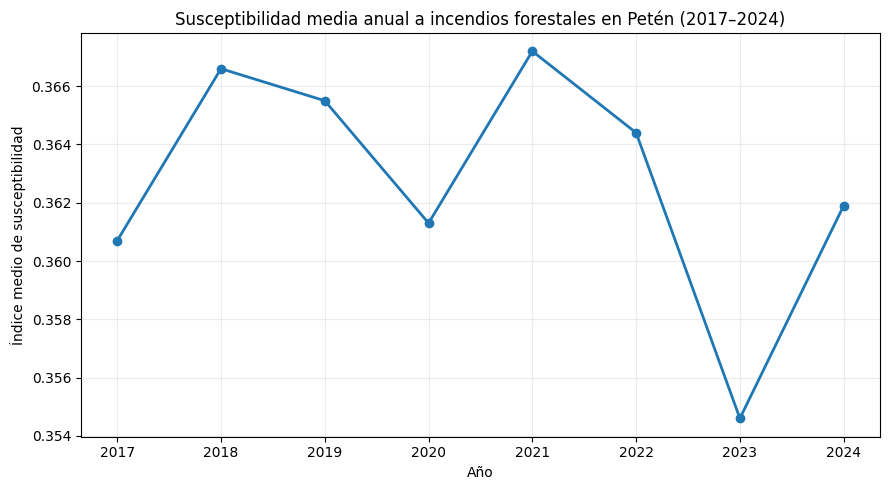

In [106]:
import matplotlib.pyplot as plt

anios = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
promedios = [0.3607, 0.3666, 0.3655, 0.3613, 0.3672, 0.3644, 0.3546, 0.3619]

plt.figure(figsize=(9, 5))

plt.plot(
    anios,
    promedios,
    marker="o",
    linewidth=2
)

plt.xlabel("Año")
plt.ylabel("Índice medio de susceptibilidad")
plt.title("Susceptibilidad media anual a incendios forestales en Petén (2017–2024)")

plt.xticks(anios)
plt.grid(True, alpha=0.25)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\susceptibilidad_media_2017_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 12.2 Importancia de las variables

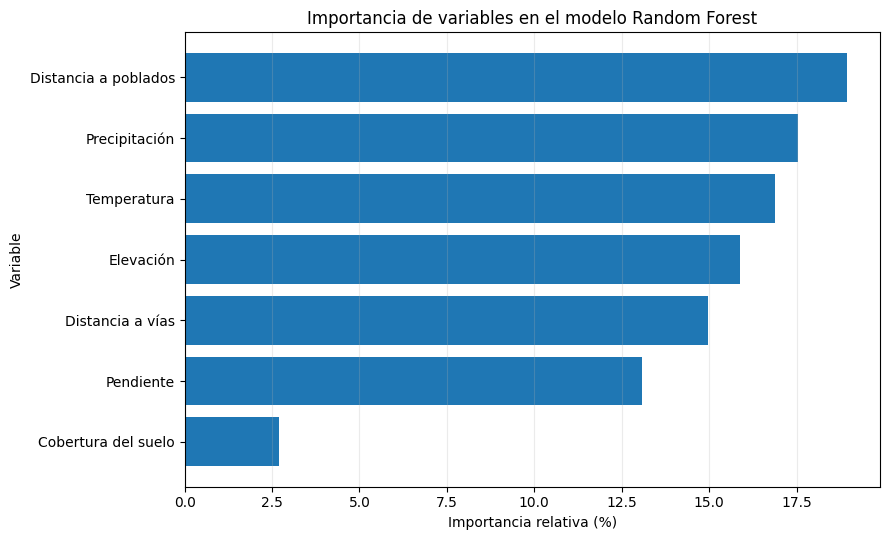

In [107]:
import matplotlib.pyplot as plt

variables_grafica = [
    "Distancia a poblados",
    "Precipitación",
    "Temperatura",
    "Elevación",
    "Distancia a vías",
    "Pendiente",
    "Cobertura del suelo"
]

importancias_grafica = [
    18.94,
    17.54,
    16.89,
    15.89,
    14.97,
    13.07,
    2.71
]

plt.figure(figsize=(9, 5.5))

plt.barh(variables_grafica[::-1], importancias_grafica[::-1])

plt.xlabel("Importancia relativa (%)")
plt.ylabel("Variable")
plt.title("Importancia de variables en el modelo Random Forest")

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\importancia_variables_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [109]:
variables = [
    ("Distancia a poblados", 18.94),
    ("Precipitación", 17.54),
    ("Temperatura", 16.89),
    ("Elevación", 15.89),
    ("Distancia a vías", 14.97),
    ("Pendiente", 13.07),
    ("Cobertura del suelo", 2.71)
]

print("VARIABLE                 | IMPORTANCIA")
print("-" * 40)

for variable, importancia in variables:
    print(f"{variable:<24} | {importancia:>6.2f}%")

VARIABLE                 | IMPORTANCIA
----------------------------------------
Distancia a poblados     |  18.94%
Precipitación            |  17.54%
Temperatura              |  16.89%
Elevación                |  15.89%
Distancia a vías         |  14.97%
Pendiente                |  13.07%
Cobertura del suelo      |   2.71%


### 12.3 Comparación de la distribución por clase: 2017–2024 y 2015–2025

In [110]:
comparacion = [
    ("Muy baja", 27.31, 27.32),
    ("Baja",     20.75, 20.19),
    ("Media",    37.46, 36.85),
    ("Alta",     13.49, 14.63),
    ("Muy alta", 0.99,  1.01)
]

print("CATEGORÍA  | 2017-2024 | 2015-2025")
print("-" * 39)

for categoria, periodo1, periodo2 in comparacion:
    print(
        f"{categoria:<10} | "
        f"{periodo1:>8.2f}% | "
        f"{periodo2:>8.2f}%"
    )

CATEGORÍA  | 2017-2024 | 2015-2025
---------------------------------------
Muy baja   |    27.31% |    27.32%
Baja       |    20.75% |    20.19%
Media      |    37.46% |    36.85%
Alta       |    13.49% |    14.63%
Muy alta   |     0.99% |     1.01%


### 12.4 Detecciones de fuego FIRMS por año

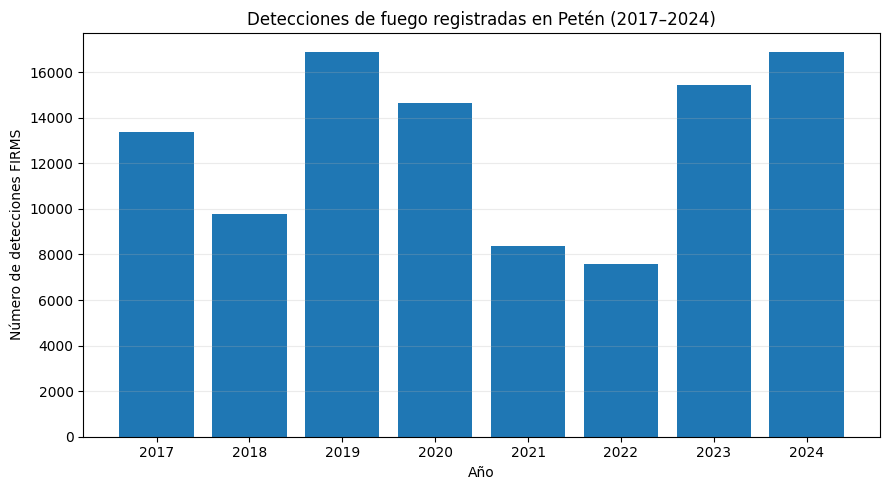

In [114]:
import matplotlib.pyplot as plt

anios = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
detecciones = [13363, 9766, 16884, 14665, 8353, 7578, 15420, 16870]

plt.figure(figsize=(9, 5))

plt.bar(anios, detecciones)

plt.xlabel("Año")
plt.ylabel("Número de detecciones FIRMS")
plt.title("Detecciones de fuego registradas en Petén (2017–2024)")
plt.xticks(anios)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    r"C:\Users\Silvia\Documents\GradIncendiosPeten\resultados\detecciones_firms_2017_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()